#Exploratory Data Analysis

This dataset is composed by 5000 CVs...

In [108]:
!pip3 install pandas
!pip install adjustText

In [133]:
import json
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns
from utils.path_loader import load_paths
from sklearn.cluster import KMeans
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from adjustText import adjust_text
import networkx as nx
import shutil
import os
from utils.path_loader import load_paths

In [135]:
paths = load_paths()
PROJECT_ROOT = paths["project_root"]

python-dotenv could not parse statement starting at line 8
python-dotenv could not parse statement starting at line 15
python-dotenv could not parse statement starting at line 20
python-dotenv could not parse statement starting at line 23
python-dotenv could not parse statement starting at line 25
python-dotenv could not parse statement starting at line 26
python-dotenv could not parse statement starting at line 27


Erro ao carregar configurações: Caminho não encontrado para PROJECT_ROOT: C:\Users\duart\OneDrive\Documentos\GitHub\Capstone\src\analysis\"C:\Users\duart\OneDrive\Documentos\GitHub\Capstone" # (põe o caminho em que está este projeto, lugar onde fizeste download do projeto)


RuntimeError: Caminho não encontrado para PROJECT_ROOT: C:\Users\duart\OneDrive\Documentos\GitHub\Capstone\src\analysis\"C:\Users\duart\OneDrive\Documentos\GitHub\Capstone" # (põe o caminho em que está este projeto, lugar onde fizeste download do projeto)

In [110]:


def readfiles(raw_data_path):
    raw_path = Path(raw_data_path)
    texts = []
    annotations_ = []

    for json_file in raw_path.rglob("*.json"):
        with open(json_file, 'r', encoding='utf-8', errors='replace') as f:
            data = json.load(f)
            
            text = data.get("text", "")
            
            # Clean lone surrogates that crash PyArrow/Pandas
            if isinstance(text, str):
                text = text.encode("utf-8", "surrogatepass").decode("utf-8", "ignore")
            
            annotations = data.get("annotations", [])

            texts.append(text)
            annotations_.append(annotations)
            
    df_skills = pd.DataFrame({"text": texts, "annotations": annotations_})
    return df_skills

In [111]:
df_skills = readfiles("data/raw/Json")

In [129]:
df_skills.head()

,text,annotations,skills_list,num_annon


In [113]:
df_skills["annotations"][0:2].tolist()

[]

In [114]:
def extract_skills(annotation_list):
    # This list comprehension pulls the string from index 2 of each sub-list
    return [item[2] for item in annotation_list]

# Create the new column
df_skills['skills_list'] = df_skills['annotations'].apply(extract_skills)

# Optional: If you want a single string separated by commas instead of a list:
# df_skills['skills_string'] = df_skills['skills_list'].apply(lambda x: ", ".join(x))

In [115]:
#Remover vazios
df_skills = df_skills[df_skills['skills_list'].apply(len) > 0].copy()

df_skills = df_skills.reset_index(drop=True)

print(f"Novo total de CVs: {len(df_skills)}")
print(df_skills.head())

Novo total de CVs: 0
Empty DataFrame
Columns: [text, annotations, skills_list]
Index: []


In [116]:
df_skills["num_annon"]=df_skills["skills_list"].apply(len)

<Axes: >

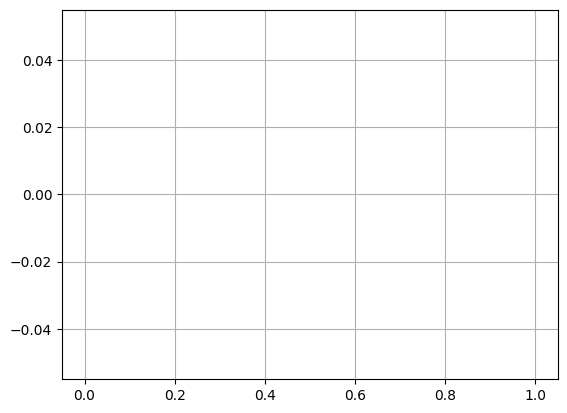

In [117]:
df_skills["num_annon"].value_counts().hist()

#Há uma tendência para os currículso terem, em média, 10 annotações.

In [118]:
unique_skills = df_skills["skills_list"].explode().unique().tolist()

In [119]:
len(unique_skills)

0

In [120]:
skill_counts = df_skills["skills_list"].apply(set).explode().value_counts()

print(skill_counts)

Series([], Name: count, dtype: int64)


In [121]:
df_skills[df_skills["skills_list"].apply(lambda x: "SKILL: COM" in x)]

""


In [122]:
#Remover Prefixo "Skill"

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda x: [item.split(': ')[-1] if ': ' in item else item for item in x]
)

In [123]:
df_skills.head()

,text,annotations,skills_list,num_annon


In [124]:
df_skills["skills_list"].explode().value_counts()

Series([], Name: count, dtype: int64)

In [125]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)

def clean_skills_text(skills_list):
    stop_words = set(stopwords.words('english'))
    cleaned_list = []
    for skill in skills_list:

        words = skill.split()
        filtered_words = [w for w in words if w.lower() not in stop_words]
        cleaned_skill = " ".join(filtered_words).strip()
        if cleaned_skill:
            cleaned_list.append(cleaned_skill)
            
    return cleaned_list

df_skills['skills_list'] = df_skills['skills_list'].apply(clean_skills_text)

df_skills['skills_list'] = df_skills['skills_list'].apply(lambda x: list(set(x)))

In [126]:
#Remover skills genéricas e não relevantes
blacklist = {"COM", "Skills" , "personal","information", "knowledge", "process", "skills", "can", "work", "marital status", "nationality", "com", "languages", "board", "email", "qualification","activities"}

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda lista: [s for s in lista if s.lower() not in blacklist]
)


In [127]:
#Normalizar

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda lista: list(set([s.lower().strip() for s in lista]))
)

print(df_skills['skills_list'].head())

df_skills["skills_list"].explode().count()

Series([], Name: skills_list, dtype: float64)


np.int64(0)

Series([], Name: count, dtype: int64)


IndexError: index 0 is out of bounds for axis 0 with size 0

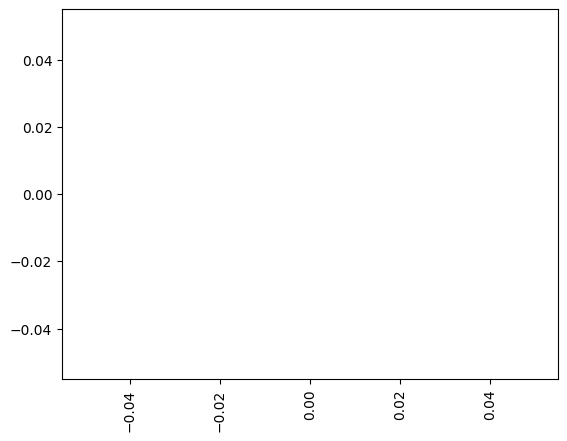

In [128]:
skill_counts = df_skills["skills_list"].apply(set).explode().value_counts()

print(skill_counts)

skill_counts.head(20).plot(kind='bar')
plt.ylabel('Frequency')
plt.xlabel('Skills names')
#Removemos conectores(e.g "is") e outras skills que não eram relevantes"

Qual será o tamanho médio dos CVs?

In [ ]:
# Configuração de caminhos

paths = load_paths()
PROJECT_ROOT = paths["project_root"]
DATA_RAW = PROJECT_ROOT/"data"/"raw"/"Json"

def analyze_cv_lengths():
    lengths = []
    file_count = 0

    print(f"🔍 Analisando ficheiros em: {DATA_RAW.resolve()}")

    for json_file in DATA_RAW.rglob("*.json"):
        try:
            data = json.loads(json_file.read_text(encoding="utf-8"))
            
            # Obtém o texto (usa .get para evitar erros se a chave faltar)
            content = data.get("text") or data.get("content")
            
            if content:
                # Mede o número de caracteres
                lengths.append(len(content))
                file_count += 1
        except Exception as e:
            print(f"❌ Erro ao ler {json_file.name}: {e}")

    if not lengths:
        print("⚠️ Nenhum dado encontrado.")
        return

    # Estatísticas básicas
    df = pd.DataFrame(lengths, columns=['length'])
    avg_len = df['length'].mean()
    median_len = df['length'].median()

    print(f"\n--- Estatísticas de Tamanho (Caracteres) ---")
    print(f"Total de CVs: {file_count}")
    print(f"Média: {avg_len:.2f}")
    print(f"Mediana: {median_len:.2f}")
    print(f"Mínimo: {df['length'].min()}")
    print(f"Máximo: {df['length'].max()}")

    # Gerar Gráfico
    plt.figure(figsize=(10, 6))
    plt.hist(lengths, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
    plt.axvline(avg_len, color='red', linestyle='dashed', linewidth=1, label=f'Média: {avg_len:.0f}')
    
    plt.title('Distribuição do Tamanho dos Currículos (Nº de Caracteres)')
    plt.xlabel('Comprimento do Texto')
    plt.ylabel('Frequência (Nº de Ficheiros)')
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    
    plt.savefig("eda_tamanho_cvs.png")
    print(f"\n✅ Gráfico guardado como 'eda_tamanho_cvs.png'")

if __name__ == "__main__":
    analyze_cv_lengths()

🔍 Analisando ficheiros em: C:\Users\duart\OneDrive\Documentos\GitHub\Capstone\src\analysis\data\raw\Json
⚠️ Nenhum dado encontrado.


Quantas skills por CV

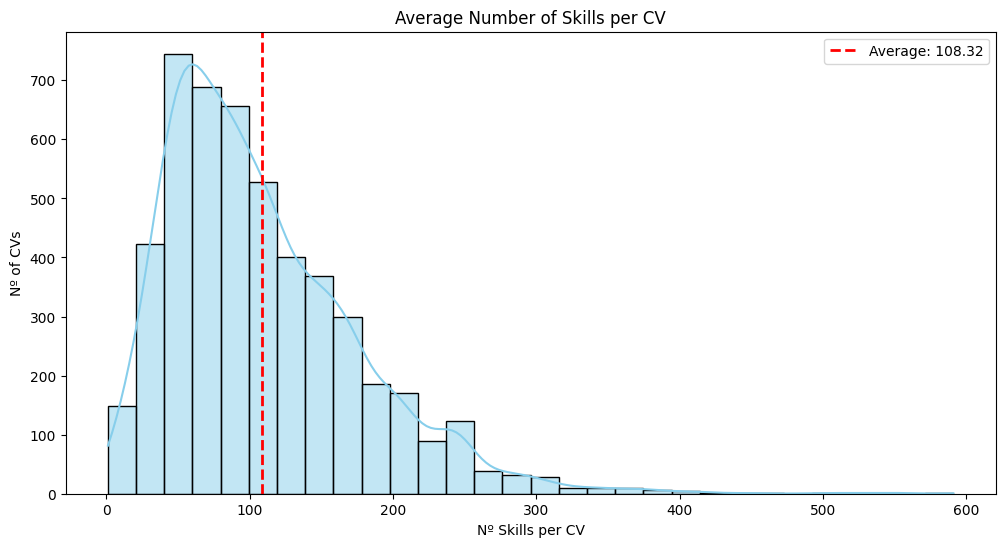

In [ ]:

media_skills = df_skills['num_annon'].mean()

plt.figure(figsize=(12, 6))
sns.histplot(df_skills['num_annon'], bins=30, kde=True, color='skyblue')
plt.axvline(media_skills, color='red', linestyle='--', linewidth=2, label=f'Average: {media_skills:.2f}')

plt.title('Average Number of Skills per CV')
plt.xlabel('Nº Skills per CV')
plt.ylabel('Nº of CVs')
plt.legend()
plt.show()

Será que existem skills relacionadas?

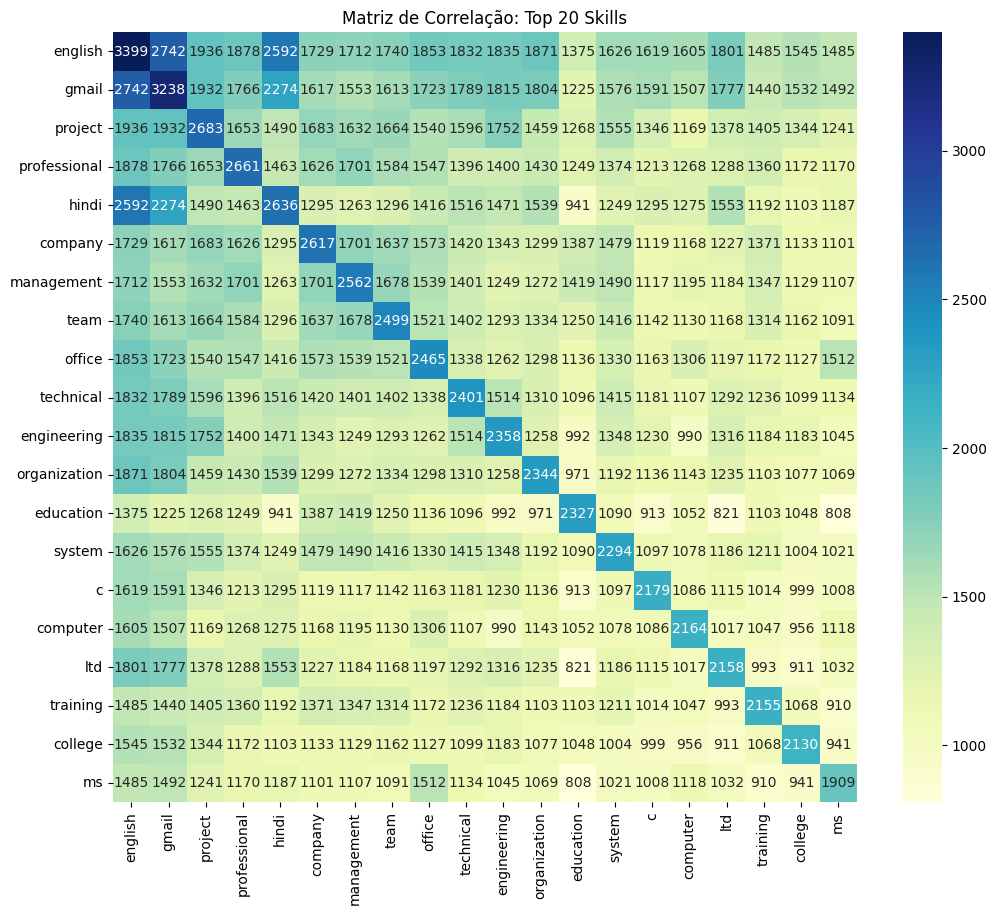

In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
skills_encoded = pd.DataFrame(mlb.fit_transform(df_skills['skills_list']), 
                             columns=mlb.classes_, 
                             index=df_skills.index)

top_20_skills = df_skills['skills_list'].explode().value_counts().head(20).index
subset_encoded = skills_encoded[top_20_skills]

co_occurrence_matrix = subset_encoded.T.dot(subset_encoded)

plt.figure(figsize=(12, 10))
sns.heatmap(co_occurrence_matrix, annot=True, fmt="d", cmap="YlGnBu")
plt.title('Matriz de Correlação: Top 20 Skills')
plt.show()

E quais são as mais raras?

In [ ]:
individual = df_skills['skills_list'].explode().value_counts()
total= df_skills['skills_list'].explode().count()
individual_pct = (individual / total) * 100

skills_stats = pd.DataFrame({
    'contagem': individual,
    'percentagem': individual_pct
})

limite_raridade = 0.15
skills_raras = skills_stats[skills_stats['percentagem'] < limite_raridade]

print(f"Total de skills únicas: {len(individual)}")
print(f"Total de skills raras (<{limite_raridade}%): {len(skills_raras)}")
print(f"Skills restantes (>={limite_raridade}%): {len(individual) - len(skills_raras)}")
print("\nExemplos de Skills Raras:")
print(skills_raras.tail(30))

Total de skills únicas: 12569
Total de skills raras (<0.15%): 12449
Skills restantes (>=0.15%): 120

Exemplos de Skills Raras:
                              contagem  percentagem
skills_list                                        
credit review                        1     0.000202
quantitative modeling                1     0.000202
cash flow modeling                   1     0.000202
law degree                           1     0.000202
correspondence preparation           1     0.000202
legal assistance                     1     0.000202
client focus                         1     0.000202
bain                                 1     0.000202
oid                                  1     0.000202
advanced research                    1     0.000202
independent decision making          1     0.000202
language fluency                     1     0.000202
medical imaging                      1     0.000202
pharmacovigilance                    1     0.000202
clinical teams                       1   

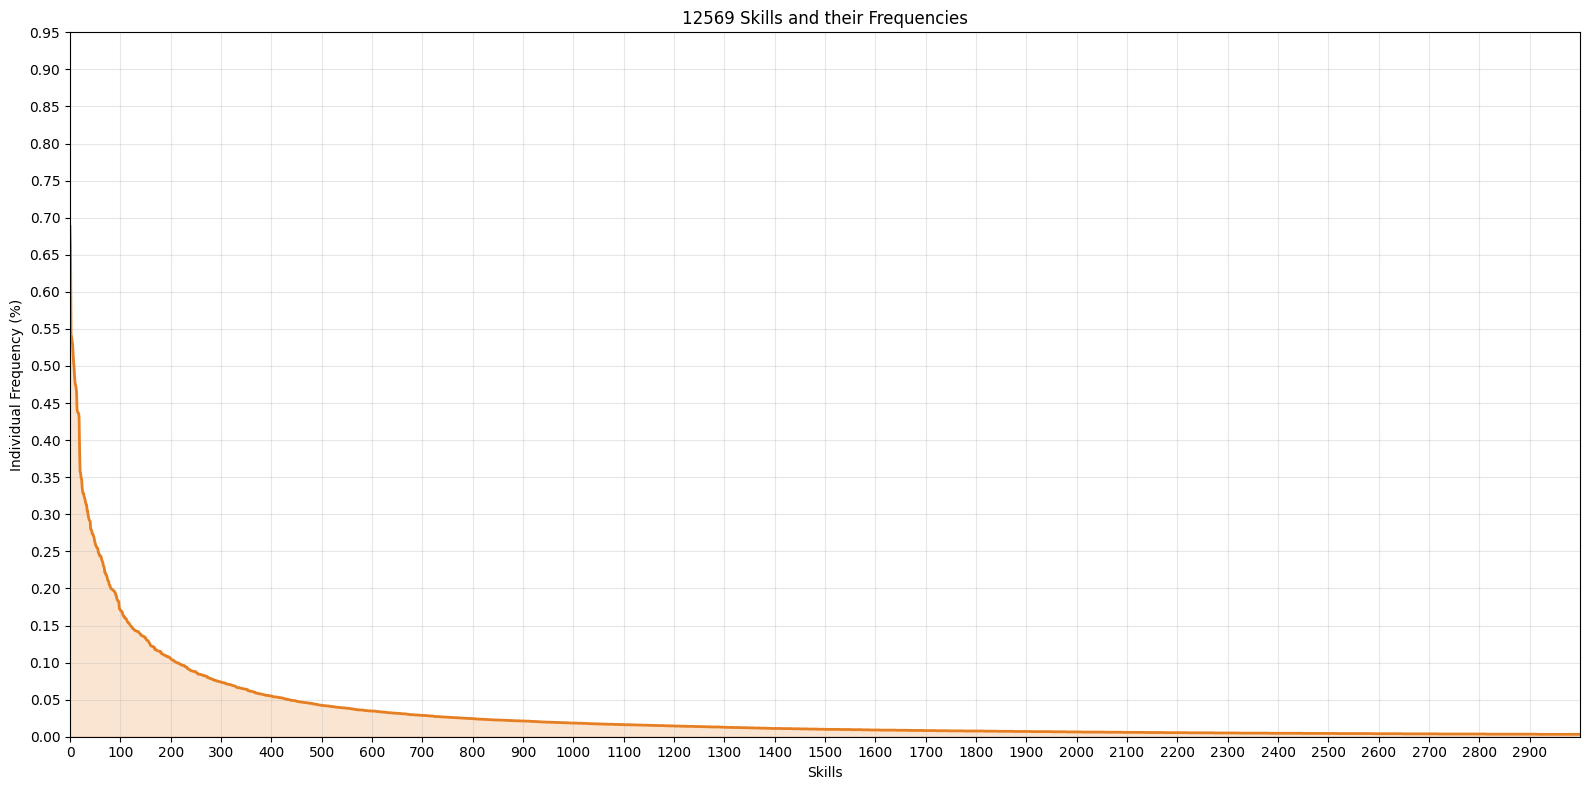

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

individual = df_skills['skills_list'].explode().value_counts()
total= df_skills['skills_list'].explode().count()
individual_pct = (individual / total) * 100

y_values = individual_pct.values
x_values = np.arange(len(y_values))

plt.figure(figsize=(16, 8))
plt.plot(x_values, y_values, color='#e67e22', linewidth=2)
plt.fill_between(x_values, y_values, color='#e67e22', alpha=0.2)

plt.xlabel('Skills')
plt.ylabel('Individual Frequency (%)')
plt.title(f'{len(y_values)} Skills and their Frequencies')

plt.xlim(0, 3000)
plt.xticks(np.arange(0, 3000, 100))
plt.grid(True, axis='both', ls="-", alpha=0.3)

if len(y_values) > 0:
    plt.ylim(0, y_values.max() * 1.1)
    plt.yticks(np.arange(0, 1, 0.05))
plt.tight_layout()
plt.show()

Vamos remover as mais raras (menos de 0.01%)

In [ ]:
import pandas as pd
import os

individual = df_skills['skills_list'].explode().value_counts()
total = df_skills['skills_list'].explode().count()
individual_pct = (individual / total) * 100

skills_validas = set(individual_pct[individual_pct >= 0.01].index)

df_skills_limpo = df_skills.copy()
df_skills_limpo['skills_list'] = df_skills_limpo['skills_list'].apply(
    lambda lista: [skill for skill in lista if skill in skills_validas]
)

df_skills_limpo = df_skills_limpo[df_skills_limpo['skills_list'].apply(len) > 0].reset_index(drop=True)

output_dir = 'data/processed/skills_filtradas'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

df_skills_limpo.to_pickle(os.path.join(output_dir, 'df_skills_final.pkl'))

display(df_skills_limpo.head())

,text,annotations,skills_list,num_annon
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[java, recognition, science, engineering, spac...",70
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[company, masters, parking, deep learning, sol...",32
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[company, meetings, goals, location, teaching,...",52
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[company, transport, xp, academic, internet, o...",42
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[regression, gmail, life, aggregate, java, cri...",80
